In [78]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from itertools import cycle
import math

In [79]:
data_dir = Path("data")

instances = pd.read_csv(data_dir / "instances.csv")
instances

,Unnamed: 0,lambda,n_updates,h_file,start_temp,end_temp,out_file
0,0,0.000000,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,data/out_l0.0.csv
1,1,0.142857,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,data/out_l0.14285714285714285.csv
2,2,0.285714,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,data/out_l0.2857142857142857.csv
3,3,0.428571,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,data/out_l0.42857142857142855.csv
4,4,0.571429,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,data/out_l0.5714285714285714.csv
5,5,0.714286,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,data/out_l0.7142857142857142.csv
6,6,0.857143,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,data/out_l0.8571428571428571.csv
7,7,1.000000,100,instances/cluster_chain_n4_e-4.0000.txt,10.0,10.0,data/out_l1.0.csv


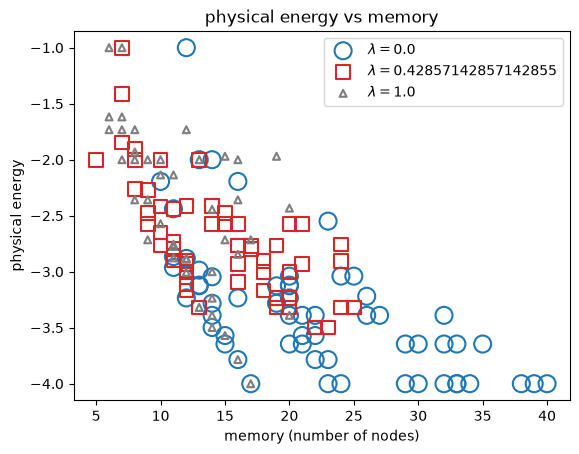

In [90]:
markers = cycle(["o", "s", "^", "D", "v", "P"])
# Scales marker area (points^2) from outer ring to inner ring based on series count
sizes = np.linspace(150, 25, len(instances))

fig, ax = plt.subplots()

keep_indices = [0, 3, 7]

for i, (index, row) in enumerate(instances.iterrows()):
    if not Path(row["out_file"]).exists():
        print("skipping row")
        continue

    if index not in keep_indices:
        continue

    this_data = pd.read_csv(row["out_file"]).drop_duplicates(["memory", "energy"])
    color = f"C{i % 10}"  # Explicitly grab Matplotlib's default color cycle

    ax.scatter(
        this_data["memory"],
        this_data["energy"],
        s=sizes[i],
        marker=next(markers),
        facecolors="none",
        edgecolors=color,
        linewidths=1.5,
        label=f"$\\lambda = {row['lambda']}$",
    )

ax.legend()
plt.title("physical energy vs memory")
plt.xlabel("memory (number of nodes)")
plt.ylabel("physical energy")
plt.show()

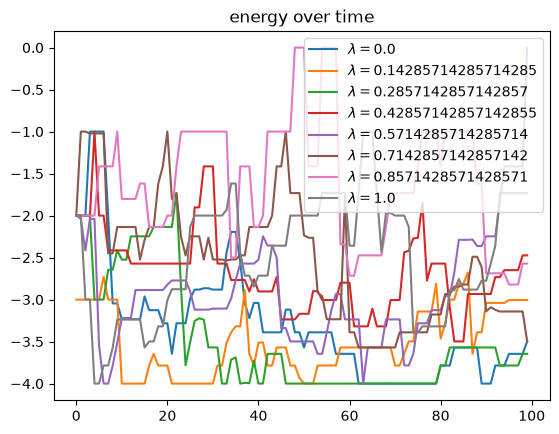

In [71]:
for index, row in instances.iterrows():
    if not Path(row["out_file"]).exists():
        continue

    this_data = pd.read_csv(row["out_file"])

    plt.plot(this_data.index, this_data["energy"], label=f"$\\lambda={row["lambda"]}$")

plt.title("energy over time")
plt.legend()

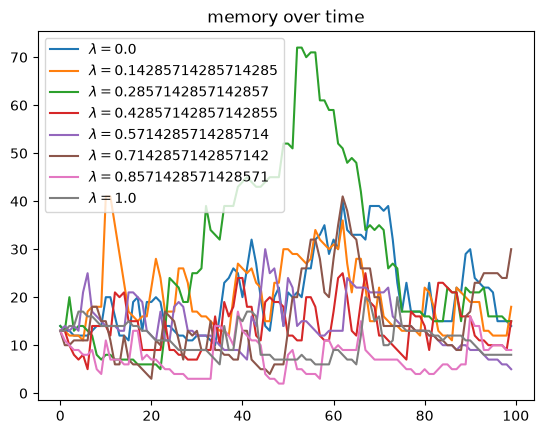

In [72]:
for index, row in instances.iterrows():
    if not Path(row["out_file"]).exists():
        continue

    this_data = pd.read_csv(row["out_file"])

    plt.plot(this_data.index, this_data["memory"], label=f"$\\lambda={row["lambda"]}$")

plt.title("memory over time")
plt.legend()